BÀI 1: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU DIABETES (EDA)
Kích thước bộ dữ liệu: 442 dòng, 11 cột

--- THỐNG KÊ MÔ TẢ 3 ĐẶC TRƯNG CHỌN ---
             mean       std       min       25%       50%       75%       max
bmi -2.245564e-16  0.047619 -0.090275 -0.034229 -0.007284  0.031248  0.170555
bp  -4.797570e-17  0.047619 -0.112399 -0.036656 -0.005670  0.035644  0.132044
s5   9.293722e-17  0.047619 -0.126097 -0.033246 -0.001947  0.032432  0.133597


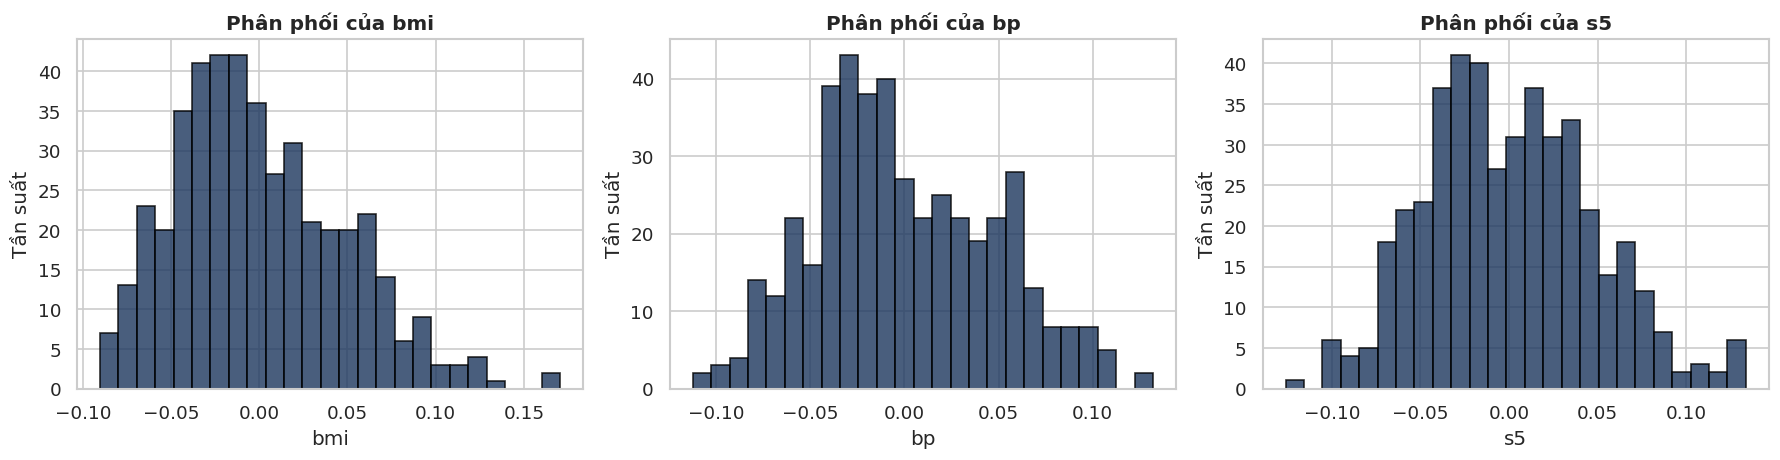


--- KẾT QUẢ PHÁT HIỆN NGOẠI LỆ THEO IQR ---
Biến      Q1     Q3    IQR  Ngưỡng dưới  Ngưỡng trên  Số ngoại lệ
 bmi -0.0342 0.0312 0.0655      -0.1324       0.1295            3
  bp -0.0367 0.0356 0.0723      -0.1451       0.1441            0
  s5 -0.0332 0.0324 0.0657      -0.1318       0.1309            4

--- HỆ SỐ TƯƠNG QUAN PEARSON VỚI TARGET ---
     Correlation_with_target
bmi                   0.5865
bp                    0.4415
s5                    0.5659


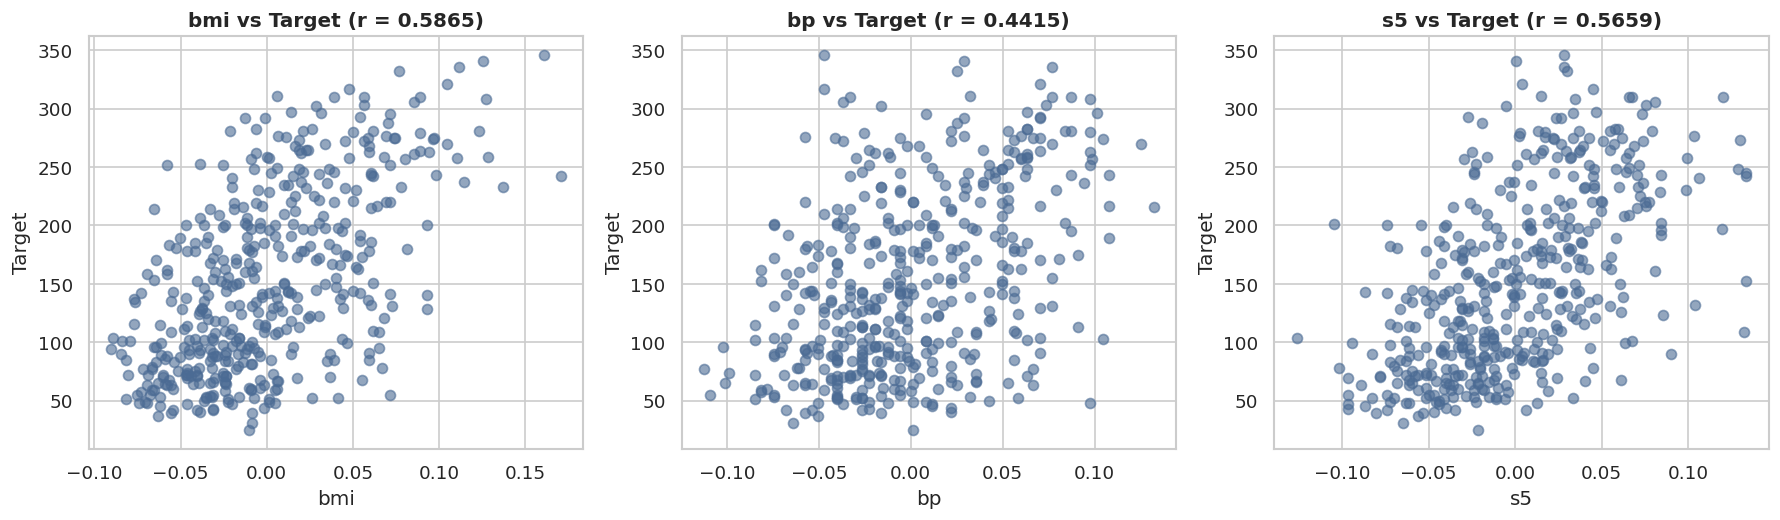


HOÀN THÀNH BÀI 1!


In [1]:
# ==============================================================================
# BÀI 1: PHÂN TÍCH VÀ KHÁM PHÁ DỮ LIỆU DIABETES (EDA 3 FEATURES)
# Tác giả: Cấn Xuân Hồng - MSSV: 24174800181 - Lớp: DHKM18A2HN
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes

# Set style biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

# 1. Tải dữ liệu Diabetes
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df['target'] = y

print("="*60)
print("BÀI 1: PHÂN TÍCH KHÁM PHÁ DỮ LIỆU DIABETES (EDA)")
print("="*60)
print(f"Kích thước bộ dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")

features = ['bmi', 'bp', 's5']

# 2. Thống kê mô tả 3 đặc trưng
print("\n--- THỐNG KÊ MÔ TẢ 3 ĐẶC TRƯNG CHỌN ---")
print(df[features].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

# 3. Phân tích phân phối (Histogram)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, col in enumerate(features):
    axes[idx].hist(df[col], bins=25, color='#1b365d', edgecolor='black', alpha=0.8)
    axes[idx].set_title(f"Phân phối của {col}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Tần suất")
plt.tight_layout()
plt.show()

# 4. Phát hiện ngoại lệ theo phương pháp IQR
outliers_summary = []
for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = int(((df[col] < lower) | (df[col] > upper)).sum())
    outliers_summary.append({
        "Biến": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Ngưỡng dưới": lower, "Ngưỡng trên": upper, "Số ngoại lệ": n_outliers
    })

outlier_df = pd.DataFrame(outliers_summary)
print("\n--- KẾT QUẢ PHÁT HIỆN NGOẠI LỆ THEO IQR ---")
print(outlier_df.round(4).to_string(index=False))

# 5. Phân tích tương quan Pearson với biến Target
correlations = df[features + ['target']].corr()['target'].drop('target')
print("\n--- HỆ SỐ TƯƠNG QUAN PEARSON VỚI TARGET ---")
print(correlations.to_frame("Correlation_with_target").round(4))

# 6. Scatter plot thể hiện mối quan hệ với Target
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for idx, col in enumerate(features):
    axes[idx].scatter(df[col], df['target'], alpha=0.6, color='#4b6b94')
    axes[idx].set_title(f"{col} vs Target (r = {correlations[col]:.4f})", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Target")
plt.tight_layout()
plt.show()

print("\nHOÀN THÀNH BÀI 1!")